# Prototipo HUD con HOE en el parabrisas: ¿qué aberraciones tiene?

Este notebook **ya está hecho**: córrelo de arriba a abajo y lee los resultados. Arma en Optiland el arreglo de la Lección 2, ahora con el **parabrisas real** (vidrios de **3 mm**), y mide qué tan bien ve el conductor.

```
 Imagen virtual  ●  1.2 m detrás del vidrio
                 ┊
 ═══════════ vidrio exterior 3 mm ═══════════
 ─────────── PVB 0.76 mm  (HOE en medio) ────
 ═══════════ vidrio interior 3 mm ═══════════
        ↑ ↓                ↖
        ↑ ↓ 0.8 m             ↖  400 mm a 45°
        ↑ ↓                      ↖
      conductor                     ▭ proyector (pantalla perpendicular a su eje)
```

| Qué se mide | Sección |
|---|---|
| El píxel del centro: ¿cambia algo por el vidrio de 3 mm? | 5 |
| Distorsión (¿se ve rectangular?) | 6 |
| Curvatura de campo y astigmatismo | 7 |
| Nitidez en todo el campo | 8 |
| Color (láser vs LED) | 9 |
| Los dos ojos y mover la cabeza | 10 |
| Imagen fantasma del vidrio | 11 |
| **Lo que ve el conductor** | 12 |
| Vista 3D | 13 |

## 0. Preparación

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import map_coordinates
from scipy.optimize import minimize_scalar
import optiland.backend as be
from optiland.optic import Optic
from optiland.materials import IdealMaterial
from optiland.phase.base import BasePhaseProfile

plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False, 'font.size': 10})
AZUL, NARANJA, AQUA, GRIS = '#2a78d6', '#eb6834', '#1baf7a', '#52514e'

## 1. Parámetros

Todo en **mm**, λ en **µm**, ángulos en **grados**. El campo de visión `FOV` es el tamaño de la imagen que ve el conductor.

In [2]:
# ---------- ARREGLO ----------
LAM      = 0.532          # λ con la que se graba el HOE y con la que proyecta el proyector [µm]
D_PROY   = 400.0          # proyector -> HOE, sobre el eje del proyector
ANG      = 45.0           # el proyector llega a 45° desde abajo
D_IMG    = 1200.0         # imagen virtual detrás del HOE
D_OJO    = 800.0          # HOE -> ojo
FOV      = (10.0, 5.0)    # campo de visión del conductor [°] (horizontal, vertical)

# ---------- PARABRISAS ----------
T_VIDRIO = 3.0            # grosor de cada vidrio
T_PVB    = 0.76           # grosor del PVB (el HOE va en medio)
VIDRIO   = IdealMaterial(n=1.518)
PVB      = IdealMaterial(n=1.479)

# ---------- OJO ----------
PUPILA   = 4.0            # diámetro de la pupila
ENFOQUE  = D_OJO + D_IMG  # el ojo enfoca a 2 m (donde debe estar la imagen)

# derivados
A   = np.radians(ANG)
P_R = np.array([0.0, -D_PROY * np.sin(A), -D_PROY * np.cos(A)])   # proyector (respecto al HOE)
P_O = np.array([0.0, 0.0, D_IMG])                                 # imagen virtual (respecto al HOE)
FX, FY = FOV[0] / 2, FOV[1] / 2
print('proyector en', np.round(P_R, 1), 'mm   imagen virtual en', P_O, 'mm')

proyector en [   0.  -282.8 -282.8] mm   imagen virtual en [   0.    0. 1200.] mm


## 2. El HOE

Es el mismo de la Lección 2, $\varphi_H = \varphi_O - \varphi_R$ con $\varphi = k_0\cdot$(distancia a la fuente), pero escrito como **fórmula** en vez de malla. Así Optiland obtiene la fase y su gradiente **exactos** en cualquier punto, sin interpolar.

Para eso se crea una clase hija de `BasePhaseProfile` (la clase base de todas las fases de Optiland) con tres métodos:
- `get_phase`: $\varphi_H(x, y)$,
- `get_gradient`: $\nabla\varphi_H$, que es lo que dobla los rayos ($\mathbf k_{sal\parallel} = \mathbf k_{ent\parallel} + \nabla\varphi$),
- `get_paraxial_gradient`: lo mismo sobre el eje y (Optiland lo pide aunque aquí no se use).

In [3]:
class HOEDosPuntos(BasePhaseProfile):
    """HOE grabado con dos ondas esféricas: R sale del punto P_R y O del punto P_O."""
    phase_type = 'hoe_dos_puntos'

    def __init__(self, P_R, P_O, lam_grabacion):
        super().__init__()
        self.R, self.O = P_R, P_O
        self.k = 2 * np.pi / (lam_grabacion * 1e-3)          # rad/mm

    def _dist(self, x, y, P):
        return be.sqrt((x - P[0])**2 + (y - P[1])**2 + P[2]**2)

    def get_phase(self, x, y, wavelength=None):
        return self.k * (self._dist(x, y, self.O) - self._dist(x, y, self.R))

    def get_gradient(self, x, y, wavelength=None):
        dO, dR = self._dist(x, y, self.O), self._dist(x, y, self.R)
        gx = self.k * ((x - self.O[0]) / dO - (x - self.R[0]) / dR)
        gy = self.k * ((y - self.O[1]) / dO - (y - self.R[1]) / dR)
        return gx, gy, be.zeros_like(x)

    def get_paraxial_gradient(self, y, wavelength=None):
        return self.get_gradient(be.zeros_like(y), y)[1]


hoe = HOEDosPuntos(P_R, P_O, LAM)

## 3. El truco: trazar **del ojo al proyector**

Optiland no deja inclinar el objeto cuando está fuera del eje: los campos `object_height` siempre quedan en un plano z = constante. Pero la pantalla del proyector tiene que estar **perpendicular al eje del proyector** (inclinada 45°); si estuviera paralela al vidrio, la imagen virtual saldría muy ladeada.

La solución es la misma que en tu Lab 2 y la que se usa en el diseño profesional de HUD: **trazar al revés**. Los rayos son reversibles: el camino proyector → ojo es el mismo que ojo → proyector.

```
 superficie:  0            1            2       3        4      5        6            7
             (∞)  ──►  OJO (pupila  ─► vidrio ─► PVB ─► HOE ─► PVB ─► vidrio ─►  PANTALLA DEL
           "a dónde     + cristalino)                  (refleja)                   PROYECTOR
            mira"                                                                  (inclinada 45°)
```

- **Campos = hacia dónde mira el conductor** (`'angle'`, en grados). `Hx = 5/campo_max` es mirar 5° a la derecha. Los campos se definen 1.5 veces más grandes que el FOV para tener margen: Optiland exige que `Hx`, `Hy` estén entre −1 y 1.
- **Superficie 1 = el ojo**: es el diafragma (pupila de 4 mm) y además una lente ideal con `f = ENFOQUE`. Al revés, esa lente hace converger los rayos al punto a 2 m que el ojo está enfocando.
- **El HOE usa la misma fase**: por la reversibilidad, $\mathbf k_{sal\parallel} = \mathbf k_{ent\parallel} + \nabla\varphi_H$ sigue valiendo al revés.
- **Superficie 7 = la pantalla**: con `dy` se baja 283 mm y con `rx = −45°` se inclina. Al ser la última superficie, Optiland sí lo permite.
- **Mover el ojo** (sección 10) = mover todo lo demás al revés, con `dx`, `dy` en las superficies 2–7.
- Si una pantalla recibe la luz en el punto (u, v), entonces el conductor, mirando en esa dirección, ve **el píxel (u, v)** del proyector.

In [4]:
def crear_hud(t_vidrio=T_VIDRIO, t_pvb=T_PVB, enfoque=ENFOQUE, lam=LAM, ojo=(0.0, 0.0)):
    ex, ey = ojo                                     # posición del ojo (mueve todo lo demás al revés)
    hud = Optic(name='HUD: del ojo al proyector')
    hud.surfaces.add(index=0, thickness=np.inf, comment='hacia donde mira')
    hud.surfaces.add(index=1, surface_type='paraxial', f=enfoque, is_stop=True,
                     thickness=D_OJO - t_vidrio - t_pvb / 2, comment='ojo')
    hud.surfaces.add(index=2, thickness=t_vidrio, material=VIDRIO, dx=-ex, dy=-ey, comment='aire -> vidrio')
    hud.surfaces.add(index=3, thickness=t_pvb / 2, material=PVB, dx=-ex, dy=-ey, comment='vidrio -> PVB')
    hud.surfaces.add(index=4, thickness=-t_pvb / 2, phase_profile=hoe, material='mirror',
                     dx=-ex, dy=-ey, comment='HOE')
    hud.surfaces.add(index=5, thickness=-t_vidrio, material=VIDRIO, dx=-ex, dy=-ey, comment='PVB -> vidrio')
    hud.surfaces.add(index=6, thickness=P_R[2] + t_vidrio + t_pvb / 2, dx=-ex, dy=-ey, comment='vidrio -> aire')
    hud.surfaces.add(index=7, dx=-ex, dy=P_R[1] - ey, rx=-A, comment='pantalla proyector')
    hud.set_aperture(aperture_type='EPD', value=PUPILA)
    hud.fields.set_type(field_type='angle')
    for ax_, ay_ in [(0, 0), (-FX, -FY), (FX, -FY), (-FX, FY), (FX, FY)]:
        hud.fields.add(x=1.5 * ax_, y=1.5 * ay_)     # 1.5×: margen para el análisis (Optiland normaliza a ±1)
    hud.wavelengths.add(value=lam, is_primary=True)
    return hud


hud = crear_hud()
hud.info()

╒════╤═══════════════╤════════════════════╤══════════╤═════════════╤════════════╤═════════╤═════════════════╕
│    │ Type          │ Comment            │   Radius │   Thickness │ Material   │   Conic │   Semi-aperture │
╞════╪═══════════════╪════════════════════╪══════════╪═════════════╪════════════╪═════════╪═════════════════╡
│  0 │ Planar        │ hacia donde mira   │      inf │     inf     │ Air        │       0 │          2      │
│  1 │ Stop - Planar │ ojo                │      inf │     796.62  │ Air        │       0 │          2      │
│  2 │ Planar        │ aire -> vidrio     │      inf │       3     │ 1.518      │       0 │         53.4166 │
│  3 │ Planar        │ vidrio -> PVB      │      inf │       0.38  │ 1.479      │       0 │         53.5442 │
│  4 │ Planar        │ HOE                │      inf │      -0.38  │ Mirror     │       0 │         53.5608 │
│  5 │ Planar        │ PVB -> vidrio      │      inf │      -3     │ 1.518      │       0 │         53.5773 │
│  6 │ Pla

/home/artis/miniconda3/envs/optica/lib/python3.14/site-packages/optiland/raytrace/paraxial_ray_tracer.py:244: ParaxialDomainWarning: paraxial ray tracing: scalar first-order results ignore surface tilts/decenters on this system (each surface is treated as centered and normal to the axis, the historical behavior):
  - [NONCOLLINEAR_VERTEX_CHAIN] surface 7: decentered surface on a straight system; scalar first-order results treat it as centered on the axis (measured 282.843 vs tolerance 8e-08)
Real ray tracing (optic.surfaces.trace) accounts for them exactly.
  path.warn_scalar_approximations(operation)


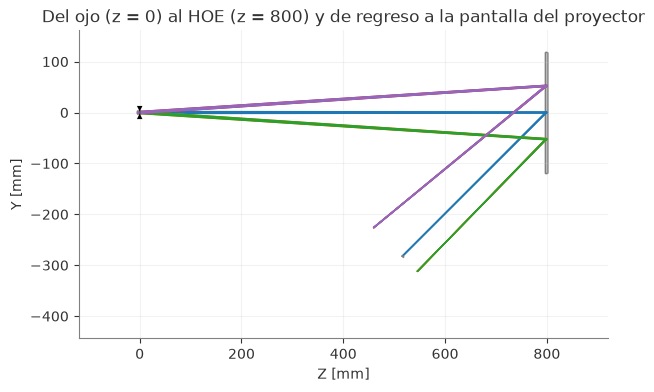

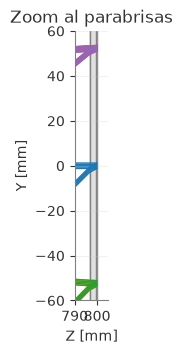

(<Figure size 800x350 with 1 Axes>,
 <Axes: title={'center': 'Zoom al parabrisas'}, xlabel='Z [mm]', ylabel='Y [mm]'>)

In [5]:
hud.draw(num_rays=5, figsize=(12, 4), title='Del ojo (z = 0) al HOE (z = 800) y de regreso a la pantalla del proyector')
hud.draw(num_rays=5, figsize=(8, 3.5), xlim=(790, 805), ylim=(-60, 60), title='Zoom al parabrisas')

## 4. Herramientas de medición

- `en_pantalla`: pasa los puntos donde cayeron los rayos a coordenadas **(u, v) de la pantalla** (u a lo ancho, v a lo alto).
- `trazar`: lanza rayos en una dirección de mirada y regresa (u, v).
- `escala`: cuántos mm de pantalla corresponden a 1° de mirada. Sirve para pasar mm a **minutos de arco** (arcmin), la unidad del ojo: alguien con vista normal distingue ~**1 arcmin**.
- `enfoque_optimo`: barre a qué distancia enfoca el ojo y busca dónde la mancha en la pantalla es mínima, con un abanico **vertical** (rayos en y) y otro **horizontal** (en x). Esa es la **distancia de la imagen virtual** que percibe el ojo; si las dos son distintas, hay **astigmatismo**. Se da en **dioptrías** (1/m), como el oculista.
- `mancha_arcmin`: qué tan borroso se ve un punto con el ojo enfocado a 2 m.

In [6]:
def en_pantalla(h):
    """Coordenadas (u, v) [mm] en la pantalla del proyector de los rayos recién trazados."""
    s = h.surfaces
    cs = s[-1].geometry.cs
    x, y, z = (be.to_numpy(a) for a in (s.x[-1], s.y[-1], s.z[-1]))
    u = x - float(cs.x)
    v = (y - float(cs.y)) * np.cos(A) - (z - float(cs.z)) * np.sin(A)
    return u, v


def trazar(h, ax, ay, Px=0.0, Py=0.0, lam=LAM):
    """El conductor mira a (ax, ay) grados; los rayos pasan por (Px, Py) de su pupila."""
    F = h.fields.max_field
    h.trace_generic(Hx=np.asarray(ax) / F, Hy=np.asarray(ay) / F, Px=Px, Py=Py, wavelength=lam)
    return en_pantalla(h)


def escala(h, ax=0.0, ay=0.0, lam=LAM, d=0.05):
    """(du/dax, dv/day) en mm de pantalla por grado de mirada."""
    u1, _ = trazar(h, ax - d, ay, lam=lam); u2, _ = trazar(h, ax + d, ay, lam=lam)
    _, v1 = trazar(h, ax, ay - d, lam=lam); _, v2 = trazar(h, ax, ay + d, lam=lam)
    return float(u2[0] - u1[0]) / (2 * d), float(v2[0] - v1[0]) / (2 * d)


def enfoque_optimo(h, ax=0.0, ay=0.0, lam=LAM):
    """Dioptrías [1/m] a las que el ojo ve nítido el abanico vertical y el horizontal."""
    P = np.linspace(-1, 1, 9)
    lente = h.surfaces[1].interaction_model
    res = []
    for eje in ('vertical', 'horizontal'):
        def dispersion(D):
            lente.f = be.array(1000.0 / D)
            u, v = trazar(h, ax, ay, 0 * P, P, lam) if eje == 'vertical' else trazar(h, ax, ay, P, 0 * P, lam)
            return float(np.std(v if eje == 'vertical' else u))
        res.append(minimize_scalar(dispersion, bounds=(0.05, 2.0), method='bounded',
                                   options={'xatol': 1e-5}).x)
    lente.f = be.array(float(ENFOQUE))
    return res[0], res[1]


def mancha_arcmin(h, ax=0.0, ay=0.0, lam=LAM, n=400):
    """Radio RMS de la mancha que ve el ojo (enfocado a ENFOQUE) en minutos de arco."""
    rng = np.random.default_rng(0)
    r, t = np.sqrt(rng.random(n)), 2 * np.pi * rng.random(n)
    u, v = trazar(h, ax, ay, r * np.cos(t), r * np.sin(t), lam)
    eu, ev = escala(h, ax, ay, lam)
    return 60 * np.hypot(np.std(u) / abs(eu), np.std(v) / abs(ev))

**Comprobación.** Sin vidrio, el HOE es "perfecto" por construcción: mirando al frente, el ojo tiene que caer en el **centro de la pantalla**, ver nítido a **2 m (0.5 D)** y sin mancha. Si esto no sale, algo está mal armado.

In [7]:
ideal = crear_hud(t_vidrio=0.0, t_pvb=0.0)
u, v = trazar(ideal, 0, 0)
Dv, Dh = enfoque_optimo(ideal)
print(f'mirando al frente cae en u = {u[0]:+.4f} mm, v = {v[0]:+.4f} mm de la pantalla')
print(f'enfoque: vertical {Dv:.4f} D ({1000/Dv:.0f} mm), horizontal {Dh:.4f} D ({1000/Dh:.0f} mm)')
print(f'mancha: {mancha_arcmin(ideal):.4f} arcmin')

mirando al frente cae en u = +0.0000 mm, v = +0.0000 mm de la pantalla
enfoque: vertical 0.5000 D (2000 mm), horizontal 0.5000 D (2000 mm)
mancha: 0.0000 arcmin


## 5. El píxel del centro: ¿qué le hace el vidrio de 3 mm?

Se compara el HOE ideal (sin vidrio) con el parabrisas real. **El HOE se grabó sin tomar en cuenta el vidrio**, así que la luz del proyector llega a él un poco distinta de como se grabó: el vidrio inclinado a 45° **desplaza** el haz y lo deforma un poco.

In [8]:
print(f'{"":22s} {"centro (u, v) [mm]":>20s} {"corrimiento":>12s} {"foco vert.":>11s} {"foco horiz.":>12s} {"astigm.":>9s} {"mancha":>8s}')
for nombre, t in [('sin vidrio (ideal)', 0.0), (f'vidrios de {T_VIDRIO} mm', T_VIDRIO)]:
    h = crear_hud(t_vidrio=t, t_pvb=T_PVB if t > 0 else 0.0)
    u, v = trazar(h, 0, 0)
    eu, ev = escala(h)
    corr = 60 * np.hypot(u[0] / eu, v[0] / ev)                # mm de pantalla -> arcmin
    Dv, Dh = enfoque_optimo(h)
    print(f'{nombre:22s} {f"({u[0]:+.3f}, {v[0]:+.3f})":>20s} {corr:9.2f} arcmin {1000/Dv:8.0f} mm {1000/Dh:9.0f} mm '
          f'{abs(Dv - Dh):7.4f} D {mancha_arcmin(h):6.3f} arcmin')

                         centro (u, v) [mm]  corrimiento  foco vert.  foco horiz.   astigm.   mancha
sin vidrio (ideal)         (+0.000, +0.000)      0.00 arcmin     2000 mm      2000 mm  0.0000 D  0.000 arcmin
vidrios de 3.0 mm          (+0.000, +1.127)      4.12 arcmin     1990 mm      1989 mm  0.0002 D  0.014 arcmin


**Cómo leerlo.**
- **corrimiento**: el píxel que se ve al frente ya no es el centro de la pantalla. Es un desplazamiento **fijo**; se corrige moviendo la imagen en el proyector (o grabando el HOE a través del vidrio).
- **foco vertical / horizontal**: distancia a la que el ojo ve nítido cada abanico. Si son distintas, es **astigmatismo**; la columna `astigm.` lo da en dioptrías. Como referencia, el ojo casi no nota menos de ~0.25 D.
- **mancha**: borrosidad con el ojo enfocado a 2 m, comparada con ~1 arcmin de resolución del ojo.

## 6. Distorsión: ¿se ve rectangular?

Se traza el rayo central (el que pasa por el centro de la pupila) para una cuadrícula de direcciones de mirada **rectangular**. Donde cae cada uno en la pantalla es **lo que el proyector tiene que dibujar para que el conductor vea un rectángulo**. Si la figura no es rectangular, hay distorsión.

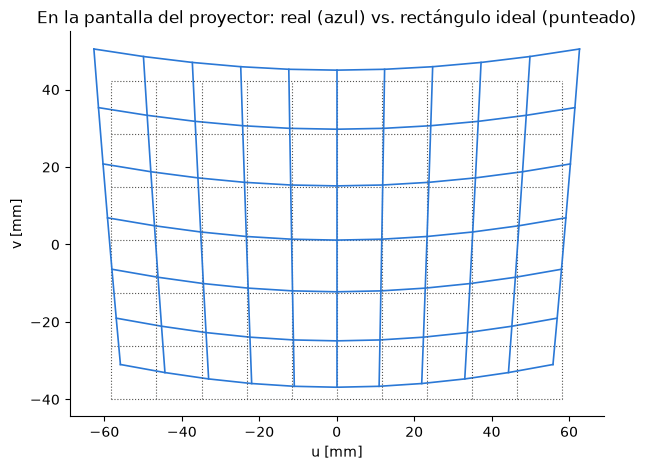

escala en el centro: +11.64 mm/° horizontal, +16.41 mm/° vertical
ancho del rectángulo arriba 125.41 mm, abajo 111.70 mm  ->  trapecio (keystone) de +12.3 %
la línea de arriba se curva -5.46 mm ("sonrisa")
distorsión máxima: 38.4 arcmin (0.64°)


In [9]:
hud = crear_hud()
gx = np.linspace(-FX, FX, 11)
gy = np.linspace(-FY, FY, 7)
GX, GY = np.meshgrid(gx, gy)
U, V = trazar(hud, GX.ravel(), GY.ravel())
U, V = U.reshape(GX.shape), V.reshape(GX.shape)

# rectángulo ideal: misma escala que en el centro
eu, ev = escala(hud)
u0, v0 = trazar(hud, 0, 0)
Ui, Vi = u0[0] + eu * GX, v0[0] + ev * GY

fig, ax = plt.subplots(figsize=(9, 5))
for k in range(GX.shape[0]):
    ax.plot(Ui[k], Vi[k], color=GRIS, lw=0.8, ls=':')
    ax.plot(U[k], V[k], color=AZUL, lw=1.2)
for k in range(GX.shape[1]):
    ax.plot(Ui[:, k], Vi[:, k], color=GRIS, lw=0.8, ls=':')
    ax.plot(U[:, k], V[:, k], color=AZUL, lw=1.2)
ax.set_aspect('equal'); ax.set_xlabel('u [mm]'); ax.set_ylabel('v [mm]')
ax.set_title('En la pantalla del proyector: real (azul) vs. rectángulo ideal (punteado)')
plt.show()

ancho_arriba = U[-1, -1] - U[-1, 0]
ancho_abajo = U[0, -1] - U[0, 0]
print(f'escala en el centro: {eu:+.2f} mm/° horizontal, {ev:+.2f} mm/° vertical')
print(f'ancho del rectángulo arriba {abs(ancho_arriba):.2f} mm, abajo {abs(ancho_abajo):.2f} mm  ->  trapecio (keystone) de '
      f'{100 * (abs(ancho_arriba) - abs(ancho_abajo)) / abs(ancho_abajo):+.1f} %')
flecha = V[-1, GX.shape[1] // 2] - (V[-1, 0] + V[-1, -1]) / 2
print(f'la línea de arriba se curva {flecha:+.2f} mm ("sonrisa")')
err = 60 * np.hypot((U - Ui) / eu, (V - Vi) / ev)
print(f'distorsión máxima: {err.max():.1f} arcmin ({err.max() / 60:.2f}°)')

**Signos de la escala.** Si `du/dax` o `dv/day` son negativos, la imagen sale **volteada** en esa dirección y el proyector tiene que mostrarla espejeada. Eso pasa con cualquier HUD, porque la imagen se ve "reflejada".

**¿Es grave?** La distorsión de un HUD casi siempre se **corrige por software**: el proyector dibuja la imagen ya deformada al revés (*pre-distorsión*). Lo que **no** se corrige así es el desenfoque, el astigmatismo y el color (secciones 7–9).

## 7. Curvatura de campo y astigmatismo

Para cada dirección de mirada se busca a qué distancia ve nítido el ojo (abanico vertical y horizontal).
- **Curvatura de campo**: la imagen virtual no está a la misma distancia en todo el campo.
- **Astigmatismo**: los dos abanicos enfocan a distancias distintas.

Fíjate en el abanico vertical: **arriba la imagen queda más cerca y abajo más lejos**. La imagen virtual no es un plano de frente al conductor, sino un plano **inclinado**. Es el precio de usar el HOE fuera de eje (45°): la pantalla del proyector está inclinada respecto al rayo central y el HOE "amplifica" esa inclinación (regla de Scheimpflug).

listo en 3.1 s


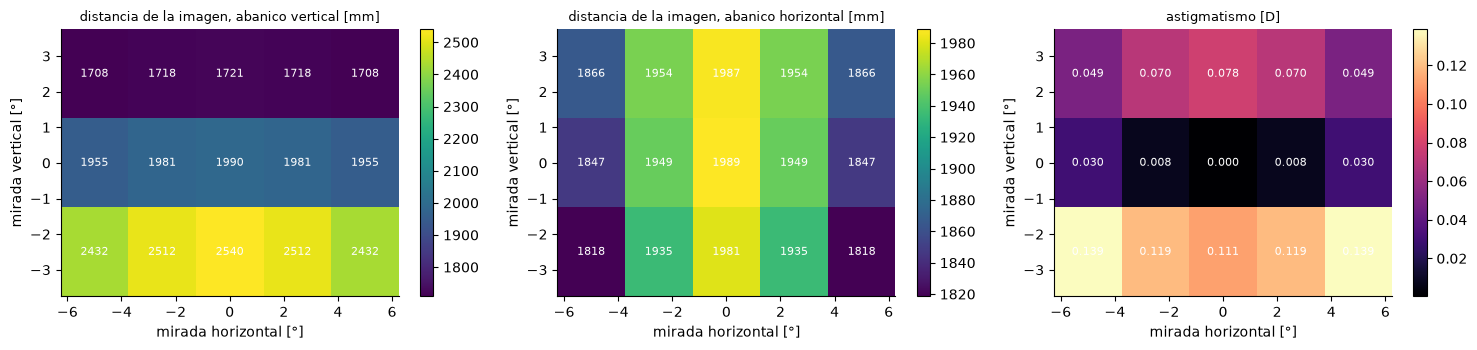

distancia de la imagen (promedio de los dos abanicos): de 1784 a 2226 mm
abanico vertical: arriba 1715 mm, abajo 2485 mm  ->  la imagen está INCLINADA
variación de la distancia: 0.111 D     astigmatismo máximo: 0.139 D


In [10]:
gx7 = np.linspace(-FX, FX, 5)
gy7 = np.linspace(-FY, FY, 3)
Dv7 = np.zeros((len(gy7), len(gx7)))
Dh7 = np.zeros_like(Dv7)
t0 = time.time()
for i, ay_ in enumerate(gy7):
    for j, ax_ in enumerate(gx7):
        Dv7[i, j], Dh7[i, j] = enfoque_optimo(hud, ax_, ay_)
print(f'listo en {time.time() - t0:.1f} s')

fig, axs = plt.subplots(1, 3, figsize=(15, 3.6))
dx7, dy7 = gx7[1] - gx7[0], gy7[1] - gy7[0]
ext = [-FX - dx7 / 2, FX + dx7 / 2, -FY - dy7 / 2, FY + dy7 / 2]
for a, dato, titulo, cmap in [(axs[0], 1000 / Dv7, 'distancia de la imagen, abanico vertical [mm]', 'viridis'),
                              (axs[1], 1000 / Dh7, 'distancia de la imagen, abanico horizontal [mm]', 'viridis'),
                              (axs[2], np.abs(Dv7 - Dh7), 'astigmatismo [D]', 'magma')]:
    im = a.imshow(dato, extent=ext, origin='lower', cmap=cmap, aspect='auto')
    for i, ay_ in enumerate(gy7):
        for j, ax_ in enumerate(gx7):
            a.text(ax_, ay_, f'{dato[i, j]:.0f}' if dato.max() > 10 else f'{dato[i, j]:.3f}',
                   ha='center', va='center', fontsize=8, color='w')
    fig.colorbar(im, ax=a); a.set_title(titulo, fontsize=9)
    a.set_xlabel('mirada horizontal [°]'); a.set_ylabel('mirada vertical [°]')
plt.tight_layout(); plt.show()

Dm = (Dv7 + Dh7) / 2
print(f'distancia de la imagen (promedio de los dos abanicos): de {1000 / Dm.max():.0f} a {1000 / Dm.min():.0f} mm')
print(f'abanico vertical: arriba {1000 / Dv7[-1].mean():.0f} mm, abajo {1000 / Dv7[0].mean():.0f} mm  ->  la imagen está INCLINADA')
print(f'variación de la distancia: {Dm.max() - Dm.min():.3f} D     astigmatismo máximo: {np.abs(Dv7 - Dh7).max():.3f} D')

## 8. Nitidez en todo el campo

Radio RMS de la mancha con el ojo enfocado a **2 m**, en arcmin. Junta todo: astigmatismo, curvatura de campo y el resto de las aberraciones.

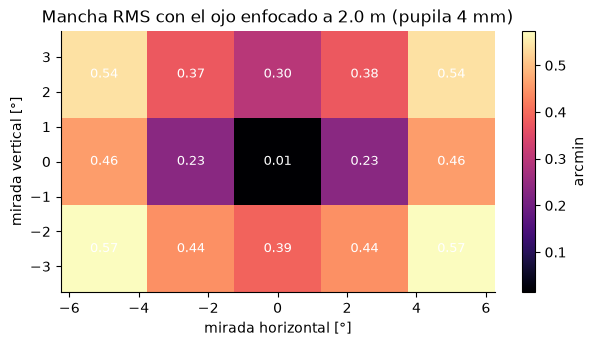

mancha: mínima 0.01, máxima 0.57 arcmin   (el ojo resuelve ~1 arcmin)


In [11]:
M8 = np.array([[mancha_arcmin(hud, ax_, ay_) for ax_ in gx7] for ay_ in gy7])
fig, a = plt.subplots(figsize=(7, 3.4))
im = a.imshow(M8, extent=ext, origin='lower', cmap='magma', aspect='auto')
for i, ay_ in enumerate(gy7):
    for j, ax_ in enumerate(gx7):
        a.text(ax_, ay_, f'{M8[i, j]:.2f}', ha='center', va='center', fontsize=9, color='w')
fig.colorbar(im, ax=a, label='arcmin')
a.set_xlabel('mirada horizontal [°]'); a.set_ylabel('mirada vertical [°]')
a.set_title(f'Mancha RMS con el ojo enfocado a {ENFOQUE / 1000:.1f} m (pupila {PUPILA:.0f} mm)')
plt.show()
print(f'mancha: mínima {M8.min():.2f}, máxima {M8.max():.2f} arcmin   (el ojo resuelve ~1 arcmin)')

## 9. Color: láser vs. LED

El HOE es una **rejilla**, y una rejilla desvía distinto cada color: se grabó para 532 nm. Aquí se ve qué le pasa a la imagen del centro si el proyector emite otra λ.
- Un **láser** es casi monocromático (≲ 1 nm).
- Un **LED verde** tiene un ancho de ~30 nm, así que cada color del LED dibuja la imagen en otro lugar: la imagen se **embarra**.

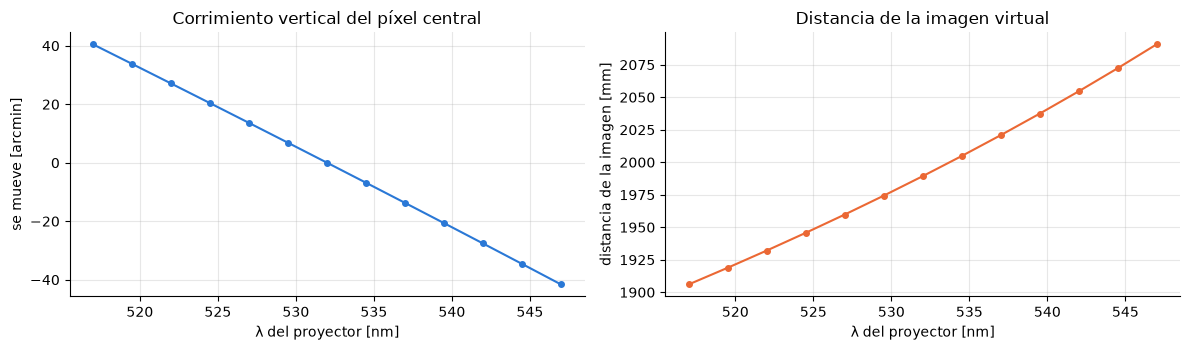

la imagen se mueve -2.7 arcmin por cada nm   ->   LED de 30 nm: se embarra ~1.4° de alto
láser de 1 nm: ~2.7 arcmin


In [12]:
lams = np.linspace(0.517, 0.547, 13)
desv, dist = [], []
for lam in lams:
    h = crear_hud(lam=lam)
    u, v = trazar(h, 0, 0, lam=lam)
    desv.append((u[0], v[0]))
    Dv, Dh = enfoque_optimo(h, lam=lam)
    dist.append(2000 / (Dv + Dh))
desv = np.array(desv)
eu, ev = escala(hud)
u0, v0 = trazar(hud, 0, 0)
corr = 60 * (desv[:, 1] - v0[0]) / ev            # arcmin (vertical)

fig, axs = plt.subplots(1, 2, figsize=(12, 3.6))
axs[0].plot(lams * 1000, corr, 'o-', color=AZUL, ms=4)
axs[0].set_xlabel('λ del proyector [nm]'); axs[0].set_ylabel('se mueve [arcmin]')
axs[0].set_title('Corrimiento vertical del píxel central'); axs[0].grid(alpha=0.3)
axs[1].plot(lams * 1000, dist, 'o-', color=NARANJA, ms=4)
axs[1].set_xlabel('λ del proyector [nm]'); axs[1].set_ylabel('distancia de la imagen [mm]')
axs[1].set_title('Distancia de la imagen virtual'); axs[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()

pend = np.polyfit(lams * 1000, corr, 1)[0]
print(f'la imagen se mueve {pend:.1f} arcmin por cada nm   ->   LED de 30 nm: se embarra ~{abs(pend) * 30 / 60:.1f}° de alto')
print(f'láser de 1 nm: ~{abs(pend):.1f} arcmin')

## 10. Los dos ojos y mover la cabeza

El conductor ve con **dos ojos** separados ~64 mm y mueve la cabeza. Para un mismo píxel del proyector se busca en qué dirección lo ve cada ojo (con Newton, porque al revés solo sabemos "miro aquí → caigo allá").
- **Diferencia vertical entre ojos** (*dipvergencia*): el cerebro tolera muy poca, unos pocos arcmin. Más que eso cansa la vista o se ve doble.
- **Distancia por convergencia**: dónde se cruzan las dos líneas de mirada. Es la distancia a la que el cerebro "cree" que está la imagen.

In [13]:
def donde_lo_veo(ojo, u_obj, v_obj, lam=LAM):
    """Dirección (ax, ay) en grados en la que el ojo en 'ojo' ve el píxel (u_obj, v_obj) de la pantalla."""
    h = crear_hud(ojo=ojo, lam=lam)
    a = np.zeros(2)
    for _ in range(8):                                # Newton 2D
        u, v = trazar(h, a[0], a[1], lam=lam)
        eu, ev = escala(h, a[0], a[1], lam=lam)
        a -= np.array([(u[0] - u_obj) / eu, (v[0] - v_obj) / ev])
    return a


def cruce(o1, d1, o2, d2):
    """Punto medio entre dos rectas o + t·d (la más cercana a cruzarse)."""
    w = o1 - o2
    a, b, c, d, e = d1 @ d1, d1 @ d2, d2 @ d2, d1 @ w, d2 @ w
    t1 = (b * e - c * d) / (a * c - b * b)
    t2 = (a * e - b * d) / (a * c - b * b)
    return (o1 + t1 * d1 + o2 + t2 * d2) / 2


IPD = 64.0
print(f'{"píxel (lo que el ojo central ve en)":36s} {"dif. vertical":>14s} {"distancia por convergencia":>27s}')
for ax_, ay_ in [(0, 0), (-FX, 0), (FX, 0), (0, FY), (0, -FY), (FX, FY), (-FX, -FY)]:
    u, v = trazar(hud, ax_, ay_)
    aL = donde_lo_veo((-IPD / 2, 0.0), u[0], v[0])
    aR = donde_lo_veo((+IPD / 2, 0.0), u[0], v[0])
    dirs = [np.array([np.tan(np.radians(a[0])), np.tan(np.radians(a[1])), 1.0]) for a in (aL, aR)]
    P = cruce(np.array([-IPD / 2, 0, 0]), dirs[0], np.array([IPD / 2, 0, 0]), dirs[1])
    print(f'  mirada ({ax_:+.1f}°, {ay_:+.1f}°){"":16s} {60 * (aL[1] - aR[1]):10.2f} arcmin {P[2]:20.0f} mm')

píxel (lo que el ojo central ve en)   dif. vertical  distancia por convergencia
  mirada (+0.0°, +0.0°)                       0.00 arcmin                 1989 mm
  mirada (-5.0°, +0.0°)                     -18.67 arcmin                 1834 mm
  mirada (+5.0°, +0.0°)                      18.67 arcmin                 1834 mm
  mirada (+0.0°, +2.5°)                       0.00 arcmin                 1987 mm
  mirada (+0.0°, -2.5°)                       0.00 arcmin                 1981 mm
  mirada (+5.0°, +2.5°)                      17.21 arcmin                 1858 mm
  mirada (-5.0°, -2.5°)                     -19.89 arcmin                 1802 mm


In [14]:
# mover la cabeza: ¿hacia dónde se va el píxel central?
u_c, v_c = trazar(hud, 0, 0)
print('ojo movido [mm]   ve el píxel central en (horiz., vert.) [°]   esperado si la imagen estuviera fija a 2 m')
for ojo in [(0, 0), (30, 0), (-30, 0), (0, 20), (0, -20)]:
    a = donde_lo_veo(ojo, u_c[0], v_c[0])
    esp = np.degrees(np.arctan(-np.array(ojo) / ENFOQUE))
    print(f'  {str(ojo):14s}   ({a[0]:+.3f}, {a[1]:+.3f}){"":22s}({esp[0]:+.3f}, {esp[1]:+.3f})')

ojo movido [mm]   ve el píxel central en (horiz., vert.) [°]   esperado si la imagen estuviera fija a 2 m
  (0, 0)           (+0.000, +0.000)                      (+0.000, +0.000)
  (30, 0)          (-0.864, +0.000)                      (-0.859, +0.000)
  (-30, 0)         (+0.864, +0.000)                      (+0.859, +0.000)
  (0, 20)          (+0.000, -0.576)                      (+0.000, -0.573)
  (0, -20)         (+0.000, +0.576)                      (+0.000, +0.573)


Si la imagen estuviera bien "anclada" a 2 m, al mover la cabeza el píxel se movería como en la columna **esperado**. Si no coincide, la imagen "nada" cuando el conductor se mueve (*distorsión dinámica*).

## 11. ¿Imagen fantasma del vidrio?

En un HUD normal el vidrio es el espejo, y la cara de atrás del vidrio da una **segunda imagen** desplazada (el fantasma). Aquí el que manda la luz al ojo es el HOE; las caras del vidrio solo reflejan como espejo plano (ley de reflexión). Se calcula cuánta luz reflejan (Fresnel) y **hacia dónde** va.

In [15]:
n = VIDRIO.n(LAM)
n = float(np.ravel(be.to_numpy(n))[0])
ti = A                                         # incidencia en la cara interior
tt = np.arcsin(np.sin(ti) / n)                 # refractado dentro del vidrio
Rs = ((np.cos(ti) - n * np.cos(tt)) / (np.cos(ti) + n * np.cos(tt)))**2
Rp = ((n * np.cos(ti) - np.cos(tt)) / (n * np.cos(ti) + np.cos(tt)))**2
print(f'cara interior a {ANG:.0f}°: refleja Rs = {100 * Rs:.1f} %, Rp = {100 * Rp:.1f} %, promedio {50 * (Rs + Rp):.1f} %')

# la reflexión normal sale al mismo ángulo hacia el otro lado: ¿pasa por el ojo?
y_en_ojo = D_OJO * np.tan(A)                   # altura a la que llega al plano del conductor
print(f'el reflejo del vidrio llega al plano del conductor {y_en_ojo:.0f} mm ARRIBA del ojo  ->  no entra a la pupila')
print(f'el HOE manda su luz por la normal: llega a {0:.0f} mm del ojo')

cara interior a 45°: refleja Rs = 9.6 %, Rp = 0.9 %, promedio 5.3 %
el reflejo del vidrio llega al plano del conductor 800 mm ARRIBA del ojo  ->  no entra a la pupila
el HOE manda su luz por la normal: llega a 0 mm del ojo


La luz que refleja el vidrio sale a 45° hacia el otro lado (al techo), mientras que el HOE manda la imagen **derecho al ojo**. Ese es justamente uno de los atractivos del HUD holográfico: **separa la imagen de los reflejos del vidrio**.

Ojo: eso solo vale para el arreglo **ideal**. Si el HOE tuviera algo de luz en otros órdenes, o si se usara otro ángulo, podría haber fantasmas, y eso no se modela aquí.

## 12. Lo que ve el conductor

Igual que tu Lab 2: para cada dirección de mirada (un píxel de lo que ve el conductor) se lanzan `n` rayos por puntos al azar de la pupila. Se ve **qué píxel de la pantalla del proyector** toca cada uno y se promedia el brillo. El ojo está enfocado a 2 m, así que la borrosidad, la distorsión y el color salen solos.

El proyector muestra una **cuadrícula + velocímetro**. Se dibuja ya **volteada** donde la escala es negativa, para que el conductor la vea derecha.

In [16]:
from matplotlib.figure import Figure
from matplotlib.backends.backend_agg import FigureCanvasAgg

# tamaño de la pantalla del proyector que cubre el FOV (con 15 % de margen)
Uc, Vc = trazar(hud, np.array([-FX, FX, -FX, FX]) * 1.15, np.array([-FY, -FY, FY, FY]) * 1.15)
SEMI_U, SEMI_V = np.abs(Uc).max(), np.abs(Vc).max()
SU, SV = np.sign(escala(hud))                 # si la imagen sale volteada en u o v


def dibujo_prueba(ancho=640, alto=320):
    """Lo que muestra el proyector: cuadrícula, marco, velocidad y flecha (blanco = luz)."""
    fig = Figure(figsize=(ancho / 100, alto / 100), dpi=100, facecolor='black')
    FigureCanvasAgg(fig)
    a = fig.add_axes([0, 0, 1, 1]); a.set_xlim(0, 1); a.set_ylim(0, 1); a.axis('off')
    for x in np.linspace(0.1, 0.9, 9):
        a.plot([x, x], [0.1, 0.9], color='white', lw=0.8, alpha=0.6)
    for y in np.linspace(0.1, 0.9, 5):
        a.plot([0.1, 0.9], [y, y], color='white', lw=0.8, alpha=0.6)
    a.plot([0.1, 0.9, 0.9, 0.1, 0.1], [0.1, 0.1, 0.9, 0.9, 0.1], color='white', lw=2.5)
    a.text(0.32, 0.5, '88', color='white', fontsize=60, ha='center', va='center', weight='bold')
    a.text(0.32, 0.2, 'km/h', color='white', fontsize=16, ha='center', va='center')
    a.annotate('', xy=(0.75, 0.75), xytext=(0.75, 0.25), arrowprops=dict(color='white', width=6, headwidth=22))
    fig.canvas.draw()
    return np.asarray(fig.canvas.buffer_rgba())[:, :, 0] / 255.0


DIBUJO = dibujo_prueba()                     # fila 0 = arriba de lo que debe ver el conductor


def lo_que_ve(h, lams=(LAM,), pesos=(1.0,), px=(360, 200), n=16, lote=300_000, margen=1.3):
    """Imagen (alto, ancho) que percibe el conductor. Cada λ con su peso (para simular un LED)."""
    ax = np.linspace(-FX, FX, px[0]) * margen
    ay = np.linspace(FY, -FY, px[1]) * margen
    AX, AY = np.meshgrid(ax, ay)
    AX, AY = AX.ravel(), AY.ravel()
    alto_d, ancho_d = DIBUJO.shape
    total = np.zeros(AX.size)
    rng = np.random.default_rng(0)
    for lam, w in zip(lams, pesos):
        for i in range(0, AX.size * n, lote):
            idx = np.arange(i, min(i + lote, AX.size * n)) // n          # a qué píxel pertenece cada rayo
            r, t = np.sqrt(rng.random(idx.size)), 2 * np.pi * rng.random(idx.size)
            u, v = trazar(h, AX[idx], AY[idx], r * np.cos(t), r * np.sin(t), lam)
            col = (SU * u + SEMI_U) / (2 * SEMI_U) * (ancho_d - 1)       # u -> columna del dibujo
            fil = (SEMI_V - SV * v) / (2 * SEMI_V) * (alto_d - 1)        # v -> fila (fila 0 = arriba)
            col, fil = np.nan_to_num(col, nan=-10), np.nan_to_num(fil, nan=-10)
            brillo = map_coordinates(DIBUJO, [fil, col], order=1, cval=0.0)
            total += w * np.bincount(idx, weights=brillo, minlength=AX.size)
    return total.reshape(px[1], px[0]) / (n * np.sum(pesos)), [ax[0], ax[-1], ay[-1], ay[0]]


t0 = time.time()
vista_laser, ext12 = lo_que_ve(hud)
print(f'láser: {time.time() - t0:.1f} s')

# LED verde: espectro gaussiano de 30 nm de ancho (FWHM) centrado en 532 nm
lams_led = np.linspace(0.512, 0.552, 9)
pesos_led = np.exp(-4 * np.log(2) * ((lams_led - LAM) / 0.030)**2)
t0 = time.time()
vista_led, _ = lo_que_ve(hud, lams_led, pesos_led)
print(f'LED: {time.time() - t0:.1f} s')

láser: 1.2 s
LED: 9.9 s


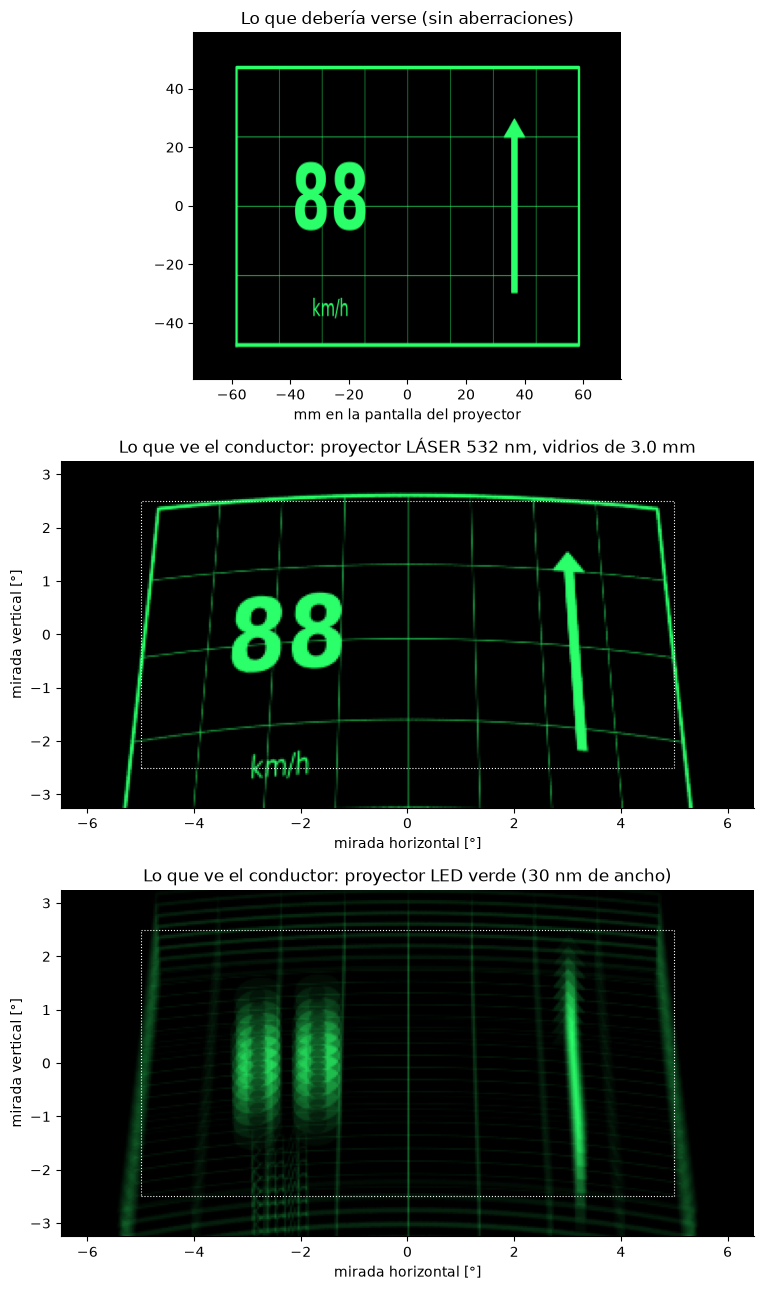

In [17]:
from matplotlib.colors import LinearSegmentedColormap
verde = LinearSegmentedColormap.from_list('verde', ['black', '#2bff6a'])

fig, axs = plt.subplots(3, 1, figsize=(10, 13))
axs[0].imshow(DIBUJO, cmap=verde, extent=[-SEMI_U, SEMI_U, -SEMI_V, SEMI_V])
axs[0].set_title('Lo que debería verse (sin aberraciones)'); axs[0].set_xlabel('mm en la pantalla del proyector')
axs[1].imshow(vista_laser, cmap=verde, extent=ext12, vmin=0, vmax=1)
axs[1].set_title(f'Lo que ve el conductor: proyector LÁSER {LAM * 1000:.0f} nm, vidrios de {T_VIDRIO} mm')
axs[2].imshow(vista_led, cmap=verde, extent=ext12, vmin=0, vmax=1)
axs[2].set_title('Lo que ve el conductor: proyector LED verde (30 nm de ancho)')
for a in axs[1:]:
    a.set_xlabel('mirada horizontal [°]'); a.set_ylabel('mirada vertical [°]')
    a.add_patch(plt.Rectangle((-FX, -FY), 2 * FX, 2 * FY, fill=False, ec='w', ls=':', lw=0.8))
plt.tight_layout(); plt.show()

## 13. Vista 3D

Como en `optica_gpu.ipynb`: la escena de Optiland más el **parabrisas** (vidrio, PVB, vidrio) y la **pantalla del proyector con su dibujo**. Los rayos van del ojo (izquierda) al HOE y bajan a la pantalla.
- `escena3D(ventana=True)` abre una ventana para girar con el mouse; la celda queda corriendo hasta que la cierres.
- `escena3D(ventana=False)` la pone como imagen dentro del notebook.

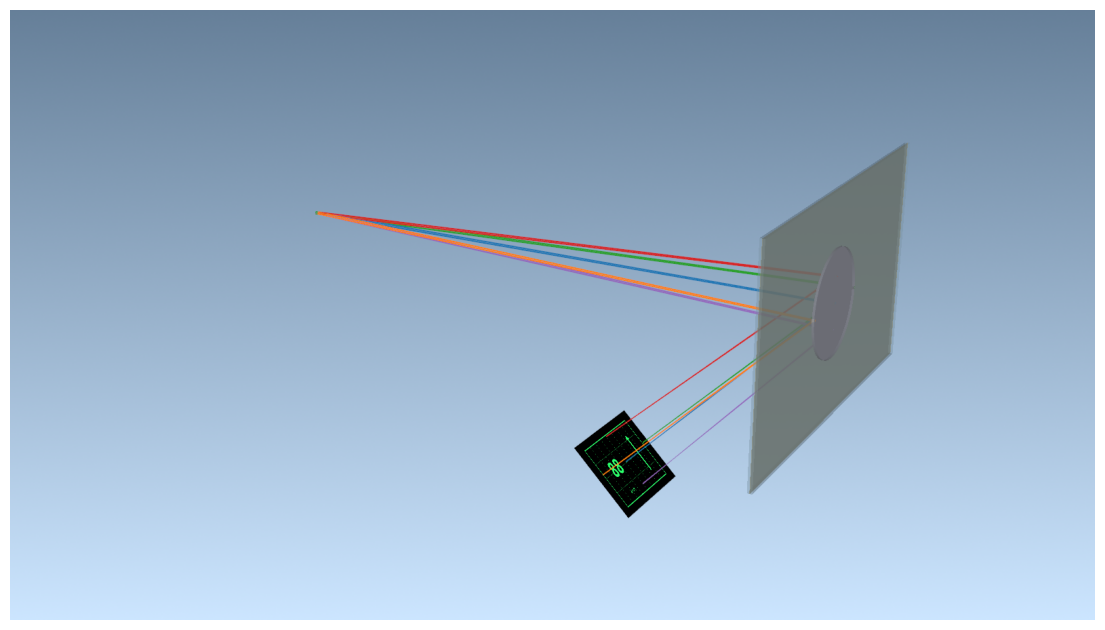

In [18]:
import vtk
from vtk.util.numpy_support import numpy_to_vtk, vtk_to_numpy
from optiland.visualization import OpticViewer3D


def plano_con_imagen(img, centro, eje_u, eje_v, semi_u, semi_v, color=(0.17, 1.0, 0.42)):
    """Rectángulo en 3D con la imagen img (fila 0 = arriba) pegada como textura."""
    a = (np.clip(np.nan_to_num(img[::-1]), 0, 1) * 255).astype(np.uint8)
    rgb = np.stack([a * color[0], a * color[1], a * color[2]], -1).astype(np.uint8)
    datos = vtk.vtkImageData(); datos.SetDimensions(a.shape[1], a.shape[0], 1)
    datos.GetPointData().SetScalars(numpy_to_vtk(rgb.reshape(-1, 3), deep=True))
    tex = vtk.vtkTexture(); tex.SetInputData(datos); tex.InterpolateOn()
    plano = vtk.vtkPlaneSource()
    plano.SetOrigin(*(centro - semi_u * eje_u - semi_v * eje_v))
    plano.SetPoint1(*(centro + semi_u * eje_u - semi_v * eje_v))
    plano.SetPoint2(*(centro - semi_u * eje_u + semi_v * eje_v))
    m = vtk.vtkPolyDataMapper(); m.SetInputConnection(plano.GetOutputPort())
    actor = vtk.vtkActor(); actor.SetMapper(m); actor.SetTexture(tex)
    actor.GetProperty().LightingOff()
    return actor


def placa(z0, z1, color, opacidad, semi=(250, 150)):
    """Capa del parabrisas entre z0 y z1."""
    caja = vtk.vtkCubeSource()
    caja.SetBounds(-semi[0], semi[0], -semi[1], semi[1], min(z0, z1), max(z0, z1))
    m = vtk.vtkPolyDataMapper(); m.SetInputConnection(caja.GetOutputPort())
    actor = vtk.vtkActor(); actor.SetMapper(m)
    actor.GetProperty().SetColor(*color); actor.GetProperty().SetOpacity(opacidad)
    return actor


def escena3D(num_rays=8, ventana=True, azimut=60, elevacion=20, acercar=1.3, tam=(1600, 900)):
    h = crear_hud()
    v3 = OpticViewer3D(h)
    if not ventana:
        v3.ren_win.SetOffScreenRendering(1)
    inicio = v3.iren.Start; v3.iren.Start = lambda: None
    F = h.fields.max_field
    v3.view(fields=[(0, 0), (-FX / F, 0), (FX / F, 0), (0, FY / F), (0, -FY / F)],
            num_rays=num_rays, figsize=tam)
    ren = v3.ren_win.GetRenderers().GetFirstRenderer()
    z_hoe = D_OJO
    ren.AddActor(placa(z_hoe - T_PVB / 2 - T_VIDRIO, z_hoe - T_PVB / 2, (0.75, 0.9, 1.0), 0.25))   # vidrio interior
    ren.AddActor(placa(z_hoe - T_PVB / 2, z_hoe + T_PVB / 2, (1.0, 0.95, 0.7), 0.35))             # PVB + HOE
    ren.AddActor(placa(z_hoe + T_PVB / 2, z_hoe + T_PVB / 2 + T_VIDRIO, (0.75, 0.9, 1.0), 0.25))   # vidrio exterior
    cs = h.surfaces[-1].geometry.cs
    centro = np.array([float(cs.x), float(cs.y), float(cs.z)])
    eje_u, eje_v = np.array([SU, 0.0, 0.0]), SV * np.array([0.0, np.cos(A), -np.sin(A)])
    ren.AddActor(plano_con_imagen(DIBUJO, centro, eje_u, eje_v, SEMI_U, SEMI_V))
    ren.ResetCamera()
    cam = ren.GetActiveCamera(); cam.Azimuth(azimut); cam.Elevation(elevacion); cam.Zoom(acercar)
    v3.ren_win.Render()
    if ventana:
        inicio()
    else:
        w = vtk.vtkWindowToImageFilter(); w.SetInput(v3.ren_win); w.Update()
        img = w.GetOutput(); nx, ny, _ = img.GetDimensions()
        pix = vtk_to_numpy(img.GetPointData().GetScalars()).reshape(ny, nx, -1)[::-1]
        plt.figure(figsize=(14, 8)); plt.imshow(pix); plt.axis('off'); plt.show()
    v3.ren_win.Finalize()


escena3D(ventana=False)      # imagen dentro del notebook
# escena3D(ventana=True)     # ventana para rotar y hacer zoom

## 14. Resumen

Resultados con los parámetros de la sección 1 (λ = 532 nm, proyector a 400 mm y 45°, imagen a 1.2 m, ojo a 0.8 m, FOV 10° × 5°, vidrios de 3 mm). **Si cambias parámetros, esta tabla no se actualiza sola**: lee los números de cada sección.

| | Resultado | ¿Importa? |
|---|---|---|
| **Vidrio de 3 mm** | corre la imagen **4.1 arcmin** (1.1 mm en la pantalla del proyector); foco a 1990 mm en vez de 2000; astigmatismo 0.0002 D; mancha 0.014 arcmin | Casi nada. El corrimiento es fijo y se corrige moviendo la imagen en el proyector |
| **Distorsión** | trapecio de **12 %**, "sonrisa" (líneas horizontales curvas), hasta **38 arcmin** (0.64°) | Se nota, pero se corrige por software (pre-distorsión) |
| **Distancia de la imagen** | de **~1.7 m arriba a ~2.5 m abajo** (abanico vertical): la imagen está **inclinada** | Moderado: el ojo tiene que reenfocar al ir de arriba a abajo |
| **Astigmatismo** | hasta **0.14 D** (en la parte de abajo) | Por debajo de ~0.25 D, casi no se nota |
| **Nitidez** (ojo enfocado a 2 m) | mancha de **0.01 a 0.57 arcmin** | Más fina de lo que resuelve el ojo (~1 arcmin) |
| **Color** | **2.7 arcmin por nm**; un LED de 30 nm embarra la imagen **~1.4°** | **El problema más grande**: hace falta un láser o un LED con filtro angosto |
| **Dos ojos** | diferencia vertical **0 en el centro** y hasta **~20 arcmin** en las orillas izquierda y derecha | **Importante**: se pide que sea de pocos arcmin; en las orillas puede cansar la vista o verse doble |
| **Mover la cabeza** | el píxel central se mueve casi como si estuviera fijo a 2 m (0.864° vs 0.859°) | Bien |
| **Fantasma del vidrio** | el reflejo de la cara interior (5 %) sale hacia el techo | No llega al ojo |

**En una frase:** el vidrio de 3 mm casi no afecta. Lo que limita el prototipo es (1) el **color**, porque el HOE es una rejilla y dispersa mucho, y (2) las aberraciones de usar el HOE **fuera de eje a 45°**: distorsión, imagen inclinada, astigmatismo y diferencia entre ojos en las orillas.

**Ideas para mejorarlo** (cada una es un experimento con este notebook):
- Proyector **láser**, o LED con filtro (prueba un ancho de 5 nm en la sección 12).
- **Grabar el HOE a través del vidrio**, con las mismas ondas que va a ver: quita el corrimiento de 4 arcmin.
- Cambiar el **ángulo** (`ANG`) o la distancia del proyector (`D_PROY`) y ver cómo cambian la distorsión, la inclinación y la diferencia entre ojos.
- Inclinar la pantalla del proyector distinto de 45° (`rx` de la superficie 7) para enderezar la imagen virtual (Scheimpflug).
- Un HOE grabado con ondas **no esféricas** (*freeform*), que es lo que se hace en los HUD holográficos comerciales.

**Lo que este modelo NO incluye:** la eficiencia de Bragg (cuánta luz difracta el HOE en cada ángulo y λ: eso está en tu `laboratorio_hoe.ipynb`), la difracción (con pupila de 4 mm es ~0.5 arcmin), la contracción de la película al laminar y la curvatura real del parabrisas (aquí es plano).